In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
)

RANDOM_STATE = 42

DATA_URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

COLUMNS = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
]

FEATURES = COLUMNS[:-1]
TARGET = "Outcome"

INVALID_ZERO_COLUMNS = [
    "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"
]

pd.set_option("display.max_columns", None)

In [17]:
df = pd.read_csv(DATA_URL, header=None, names=COLUMNS)

print(f"Dataset shape: {df.shape}")
display(df.head())

print("\nTarget distribution:")
display(df[TARGET].value_counts().rename("count").to_frame())

print("\nTarget proportions:")
display(df[TARGET].value_counts(normalize=True).rename("proportion").to_frame())

Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Target distribution:


,count
Outcome,
0,500
1,268



Target proportions:


,proportion
Outcome,
0,0.651042
1,0.348958


In [18]:
zero_counts = (df[INVALID_ZERO_COLUMNS] == 0).sum().sort_values(ascending=False)

print("Physiologically impossible zero counts:")
display(zero_counts.rename("Zero_Count").to_frame())
print(f"Total invalid zero entries: {int(zero_counts.sum())}")

Physiologically impossible zero counts:


,Zero_Count
Insulin,374
SkinThickness,227
BloodPressure,35
BMI,11
Glucose,5


Total invalid zero entries: 652


In [19]:
X = df[FEATURES].copy()
y = df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")

split_summary = pd.DataFrame({
    "Train": y_train.value_counts(normalize=True).sort_index(),
    "Test": y_test.value_counts(normalize=True).sort_index()
})
split_summary.index = ["No Diabetes (0)", "Diabetes (1)"]
display(split_summary)

X_train shape: (614, 8)
X_test shape:  (154, 8)


,Train,Test
No Diabetes (0),0.651466,0.649351
Diabetes (1),0.348534,0.350649


In [20]:
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

for col in INVALID_ZERO_COLUMNS:
    X_train_clean.loc[X_train_clean[col] == 0, col] = np.nan
    X_test_clean.loc[X_test_clean[col] == 0, col] = np.nan

print("Missing values created from invalid zeros — training set:")
display(X_train_clean.isna().sum().rename("Missing_Count").to_frame())

train_medians = X_train_clean[INVALID_ZERO_COLUMNS].median()

X_train_clean[INVALID_ZERO_COLUMNS] = X_train_clean[INVALID_ZERO_COLUMNS].fillna(train_medians)
X_test_clean[INVALID_ZERO_COLUMNS] = X_test_clean[INVALID_ZERO_COLUMNS].fillna(train_medians)

print("Training medians used for imputation:")
display(train_medians.rename("Training_Median").to_frame())

print("Remaining missing values — train:", int(X_train_clean.isna().sum().sum()))
print("Remaining missing values — test: ", int(X_test_clean.isna().sum().sum()))

Missing values created from invalid zeros — training set:


,Missing_Count
Pregnancies,0
Glucose,4
BloodPressure,23
SkinThickness,175
Insulin,290
BMI,9
DiabetesPedigreeFunction,0
Age,0


Training medians used for imputation:


,Training_Median
Glucose,117.0
BloodPressure,72.0
SkinThickness,29.0
Insulin,125.0
BMI,32.4


Remaining missing values — train: 0
Remaining missing values — test:  0


In [21]:
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_clean),
    columns=FEATURES,
    index=X_train_clean.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_clean),
    columns=FEATURES,
    index=X_test_clean.index
)

print("Training means after scaling:")
display(X_train_scaled.mean().round(4).to_frame("Mean"))

print("Training standard deviations after scaling:")
display(X_train_scaled.std(ddof=0).round(4).to_frame("Std"))

Training means after scaling:


,Mean
Pregnancies,-0.0
Glucose,-0.0
BloodPressure,0.0
SkinThickness,-0.0
Insulin,-0.0
BMI,0.0
DiabetesPedigreeFunction,-0.0
Age,-0.0


Training standard deviations after scaling:


,Std
Pregnancies,1.0
Glucose,1.0
BloodPressure,1.0
SkinThickness,1.0
Insulin,1.0
BMI,1.0
DiabetesPedigreeFunction,1.0
Age,1.0


In [22]:
gnb_raw = GaussianNB()
gnb_scaled = GaussianNB()

gnb_raw.fit(X_train_clean, y_train)
gnb_scaled.fit(X_train_scaled, y_train)

pred_gnb_raw = gnb_raw.predict(X_test_clean)
pred_gnb_scaled = gnb_scaled.predict(X_test_scaled)

gnb_results = pd.DataFrame({
    "Model": [
        "Gaussian Naive Bayes (Raw)",
        "Gaussian Naive Bayes (Scaled)"
    ],
    "Accuracy": [
        accuracy_score(y_test, pred_gnb_raw),
        accuracy_score(y_test, pred_gnb_scaled)
    ],
    "F1-score": [
        f1_score(y_test, pred_gnb_raw),
        f1_score(y_test, pred_gnb_scaled)
    ]
})

display(gnb_results.round(4))

,Model,Accuracy,F1-score
0,Gaussian Naive Bayes (Raw),0.7013,0.5965
1,Gaussian Naive Bayes (Scaled),0.7013,0.5965


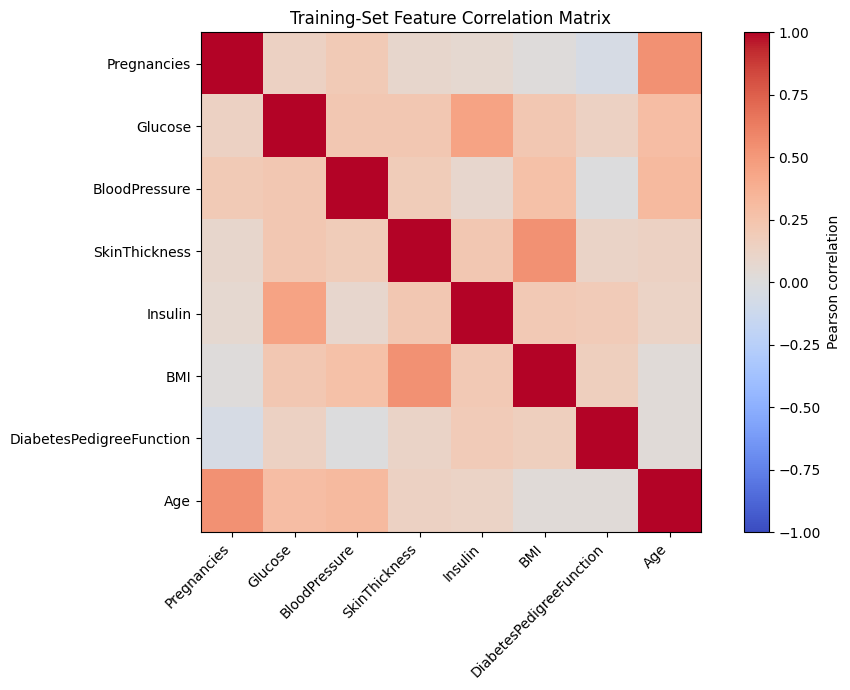

,Feature_1,Feature_2,Correlation,Absolute_Correlation
19,SkinThickness,BMI,0.5386,0.5386
6,Pregnancies,Age,0.5360,0.5360
9,Glucose,Insulin,0.4508,0.4508
17,BloodPressure,Age,0.3151,0.3151
12,Glucose,Age,0.2896,0.2896
15,BloodPressure,BMI,0.2696,0.2696
10,Glucose,BMI,0.2257,0.2257
8,Glucose,SkinThickness,0.2240,0.2240
18,SkinThickness,Insulin,0.2225,0.2225
7,Glucose,BloodPressure,0.2191,0.2191


In [23]:
corr = X_train_clean.corr()

fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)))
ax.set_yticks(range(len(FEATURES)))
ax.set_xticklabels(FEATURES, rotation=45, ha="right")
ax.set_yticklabels(FEATURES)
ax.set_title("Training-Set Feature Correlation Matrix")
fig.colorbar(im, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()

pairs = []
for i in range(len(FEATURES)):
    for j in range(i + 1, len(FEATURES)):
        pairs.append((FEATURES[i], FEATURES[j], corr.iloc[i, j]))

top_pairs = (
    pd.DataFrame(pairs, columns=["Feature_1", "Feature_2", "Correlation"])
    .assign(Absolute_Correlation=lambda d: d["Correlation"].abs())
    .sort_values("Absolute_Correlation", ascending=False)
    .head(10)
)

display(top_pairs.round(4))

**Interpretation:** substantial correlations indicate that the Naive Bayes conditional-independence assumption is imperfect. This does not automatically make GNB unusable; rather, it means the class-conditional joint distribution is being approximated with a simplified factorization. Correlated physiological variables can therefore cause GNB to double-count related evidence.

In [24]:
svc_linear = SVC(kernel="linear", random_state=RANDOM_STATE)

svc_poly = SVC(
    kernel="poly",
    degree=3,
    random_state=RANDOM_STATE
)

svc_rbf_default = SVC(
    kernel="rbf",
    probability=True,
    random_state=RANDOM_STATE
)

svc_linear.fit(X_train_scaled, y_train)
svc_poly.fit(X_train_scaled, y_train)
svc_rbf_default.fit(X_train_scaled, y_train)

pred_linear = svc_linear.predict(X_test_scaled)
pred_poly = svc_poly.predict(X_test_scaled)
pred_rbf_default = svc_rbf_default.predict(X_test_scaled)

svm_default_results = pd.DataFrame({
    "Model": [
        "SVM (Linear)",
        "SVM (Polynomial, degree=3)",
        "SVM (RBF - Default)"
    ],
    "Accuracy": [
        accuracy_score(y_test, pred_linear),
        accuracy_score(y_test, pred_poly),
        accuracy_score(y_test, pred_rbf_default)
    ],
    "F1-score": [
        f1_score(y_test, pred_linear),
        f1_score(y_test, pred_poly),
        f1_score(y_test, pred_rbf_default)
    ]
})

display(svm_default_results.round(4))

,Model,Accuracy,F1-score
0,SVM (Linear),0.7013,0.5306
1,"SVM (Polynomial, degree=3)",0.7143,0.4762
2,SVM (RBF - Default),0.7403,0.6000


In [25]:
param_grid = {
    "C": [0.1, 1, 10, 100]
}

rbf_grid = GridSearchCV(
    estimator=SVC(
        kernel="rbf",
        probability=True,
        random_state=RANDOM_STATE
    ),
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    refit=True
)

rbf_grid.fit(X_train_scaled, y_train)

print("Best C:", rbf_grid.best_params_["C"])
print("Best mean CV F1:", round(rbf_grid.best_score_, 4))

cv_results = pd.DataFrame(rbf_grid.cv_results_)[[
    "param_C",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]].sort_values("rank_test_score")

display(cv_results.round(4))

Best C: 1
Best mean CV F1: 0.6285


,param_C,mean_test_score,std_test_score,rank_test_score
1,1.0,0.6285,0.0151,1
2,10.0,0.6092,0.0654,2
3,100.0,0.5508,0.0465,3
0,0.1,0.5184,0.0470,4


In [26]:
svc_rbf_tuned = rbf_grid.best_estimator_
pred_rbf_tuned = svc_rbf_tuned.predict(X_test_scaled)

tuned_result = pd.DataFrame({
    "Model": ["SVM (RBF - Tuned)"],
    "Accuracy": [accuracy_score(y_test, pred_rbf_tuned)],
    "F1-score": [f1_score(y_test, pred_rbf_tuned)]
})

display(tuned_result.round(4))

,Model,Accuracy,F1-score
0,SVM (RBF - Tuned),0.7403,0.6


In [27]:
results = pd.concat(
    [gnb_results, svm_default_results, tuned_result],
    ignore_index=True
)

results = results.sort_values(
    ["F1-score", "Accuracy"],
    ascending=False
).reset_index(drop=True)

print("Held-out test-set performance:")
display(results.round(4))

print("Best model by held-out F1-score:", results.iloc[0]["Model"])

Held-out test-set performance:


,Model,Accuracy,F1-score
0,SVM (RBF - Default),0.7403,0.6000
1,SVM (RBF - Tuned),0.7403,0.6000
2,Gaussian Naive Bayes (Raw),0.7013,0.5965
3,Gaussian Naive Bayes (Scaled),0.7013,0.5965
4,SVM (Linear),0.7013,0.5306
5,"SVM (Polynomial, degree=3)",0.7143,0.4762


Best model by held-out F1-score: SVM (RBF - Default)


In [28]:
prediction_map = {
    "Gaussian Naive Bayes (Raw)": pred_gnb_raw,
    "Gaussian Naive Bayes (Scaled)": pred_gnb_scaled,
    "SVM (Linear)": pred_linear,
    "SVM (Polynomial, degree=3)": pred_poly,
    "SVM (RBF - Default)": pred_rbf_default,
    "SVM (RBF - Tuned)": pred_rbf_tuned,
}

clinical_metrics = []

for name, pred in prediction_map.items():
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    clinical_metrics.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall / Sensitivity": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "False Negatives": fn,
        "False Positives": fp
    })

clinical_metrics = (
    pd.DataFrame(clinical_metrics)
    .sort_values("F1-score", ascending=False)
)

display(clinical_metrics.round(4))

,Model,Accuracy,Precision,Recall / Sensitivity,F1-score,False Negatives,False Positives
4,SVM (RBF - Default),0.7403,0.6522,0.5556,0.6000,24,16
5,SVM (RBF - Tuned),0.7403,0.6522,0.5556,0.6000,24,16
1,Gaussian Naive Bayes (Scaled),0.7013,0.5667,0.6296,0.5965,20,26
0,Gaussian Naive Bayes (Raw),0.7013,0.5667,0.6296,0.5965,20,26
2,SVM (Linear),0.7013,0.5909,0.4815,0.5306,28,18
3,"SVM (Polynomial, degree=3)",0.7143,0.6667,0.3704,0.4762,34,10


##Final conclusion

After executing the notebook, use the final performance table to identify the model with the strongest held-out F1-score.

The conclusion should address:
1. Whether nonlinear kernels improved over the linear SVM.
2. Whether RBF tuning improved the default RBF model.
3. Whether GNB changed materially after standardization.
4. Whether feature correlations challenge the Naive Bayes independence assumption.
5. The precision/recall and false-negative trade-off relevant to screening.

**Do not claim that one model is clinically superior solely from this benchmark.** The Pima dataset is a historical benchmark dataset, and real clinical deployment requires substantially stronger validation.